# 신약 후보물질 독성 예측 - EDA (Day1)

- 범위: **EDA까지만** 진행한다(모델링 없음). 평가지표는 F1-score(Positive = `label` 1 = 독성 없음).
- 초점: 각 컬럼이 종속변수 `label`을 **얼마나 설명하는가**를 같은 잣대로 비교한다.
- **`label` 1 = 독성 없음, 0 = 독성 있음.** 직관과 반대다.
- 설명력 지표(모든 변수 공통): `Gini = |2·AUC − 1|` (0 = 설명력 없음, 1 = 완벽 분리).
  이진(핑거프린트 비트) 변수에서는 `|TPR − FPR|`(Youden's J)과 같다. 유의성은 연속형은 Mann-Whitney U,
  비트는 카이제곱 검정으로 구하고 전체 변수에 대해 Benjamini-Hochberg(FDR)로 보정한다.
- 주의: 라벨을 쓰는 통계는 **전체 train 기준 탐색용**이다. 특성 선택 결정은 Day2에서 분할 후 학습 데이터로 다시 한다.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import font_manager
from scipy import stats
from sklearn.metrics import f1_score, precision_recall_curve, roc_auc_score
from statsmodels.stats.multitest import multipletests

# 프로젝트 루트 찾기: 루트나 notebooks/ 어디서 실행해도 data/가 있는 폴더를 루트로 쓴다
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from features import PREFIX, compute_rdkit_descriptors  # noqa: E402

warnings.filterwarnings("ignore")

FIG = ROOT / "reports/figures"
TAB = ROOT / "reports/tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

# 색상: label 1(독성 없음) = 파랑, label 0(독성 있음) = 주황
C_POS, C_NEG = "#2a78d6", "#eb6834"
C_ACCENT = "#256abf"
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
LABEL_NAME = {1: "독성 없음(1)", 0: "독성 있음(0)"}
PAL = {1: C_POS, 0: C_NEG}

available = {f.name for f in font_manager.fontManager.ttflist}
for name in ["AppleGothic", "Apple SD Gothic Neo", "NanumGothic", "Malgun Gothic"]:
    if name in available:
        plt.rcParams["font.family"] = name
        break

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.unicode_minus": False, "axes.titlesize": 11, "axes.titleweight": "normal",
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def save(fig, name):
    fig.savefig(FIG / name)
    plt.show()

## 1. 데이터 구조

In [2]:
df = pd.read_csv(ROOT / "data/train.csv")
mem_before = df.memory_usage(deep=True).sum() / 1e6

GROUPS = {p: [c for c in df.columns if c.startswith(p + "_")] for p in ["ecfp", "fcfp", "ptfp"]}
CONT = ["MolWt", "clogp", "sa_score", "qed"]
FP_COLS = [c for cols in GROUPS.values() for c in cols]

print("고유값(핑거프린트):", sorted(np.unique(df[FP_COLS].values)))
df[FP_COLS] = df[FP_COLS].astype("uint8")  # 0/1 이진이므로 uint8로 줄인다
mem_after = df.memory_usage(deep=True).sum() / 1e6

print(f"shape = {df.shape}")
print(f"메모리: {mem_before:.0f}MB -> {mem_after:.0f}MB (핑거프린트 uint8 변환)")
print("dtypes:", df.dtypes.astype(str).value_counts().to_dict())
print({k: len(v) for k, v in GROUPS.items()}, "연속형:", CONT)
y = df["label"].values

고유값(핑거프린트): [np.int64(0), np.int64(1)]
shape = (8349, 3078)
메모리: 206MB -> 27MB (핑거프린트 uint8 변환)
dtypes: {'uint8': 3072, 'float64': 4, 'str': 1, 'int64': 1}
{'ecfp': 1024, 'fcfp': 1024, 'ptfp': 1024} 연속형: ['MolWt', 'clogp', 'sa_score', 'qed']


## 2. 타깃 변수: 클래스 균형과 F1 기준선

            건수  비율(%)
label                
독성 있음(0)  3807   45.6
독성 없음(1)  4542   54.4
F1 기준선 - 전부 1 예측: 0.7047, 전부 0 예측: 0.0000


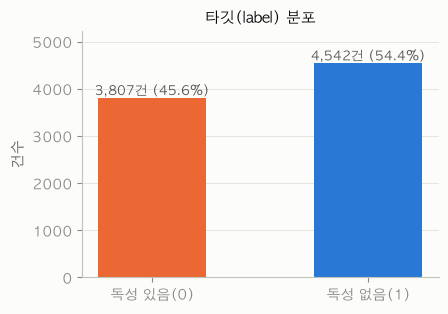

In [3]:
vc = df["label"].value_counts().sort_index()
share = vc / len(df)
print(pd.DataFrame({"건수": vc, "비율(%)": (share * 100).round(2)}).rename(index=LABEL_NAME))

# 기준선: 전부 1(독성 없음)로 예측했을 때의 F1 (Positive = 1)
f1_all_pos = f1_score(y, np.ones_like(y), pos_label=1)
f1_all_neg = f1_score(y, np.zeros_like(y), pos_label=1)
print(f"F1 기준선 - 전부 1 예측: {f1_all_pos:.4f}, 전부 0 예측: {f1_all_neg:.4f}")

fig, ax = plt.subplots(figsize=(4.6, 3.2))
bars = ax.bar([LABEL_NAME[i] for i in vc.index], vc.values, color=[PAL[i] for i in vc.index], width=0.5)
for b, v, s in zip(bars, vc.values, share.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 60, f"{v:,}건 ({s:.1%})", ha="center", color=INK2, fontsize=9)
ax.set_ylim(0, vc.max() * 1.15)
ax.set_ylabel("건수")
ax.set_title("타깃(label) 분포")
ax.grid(axis="x", visible=False)
save(fig, "01_target_distribution.png")

## 3. 데이터 품질: 결측 · 중복 · 상수열

In [4]:
quality = {
    "결측값 총합": int(df.isna().sum().sum()),
    "SMILES 고유 개수": df["SMILES"].nunique(),
    "SMILES 중복 행": int(df["SMILES"].duplicated().sum()),
    "SMILES 길이(최소/중앙/최대)": (int(df["SMILES"].str.len().min()), float(df["SMILES"].str.len().median()), int(df["SMILES"].str.len().max())),
}
for k, v in quality.items():
    print(f"{k}: {v}")

n = len(df)
rows = []
for g, cols in GROUPS.items():
    on = df[cols].sum()
    rows.append({
        "그룹": g, "비트 수": len(cols),
        "행당 ON 비트 평균": round(float(df[cols].sum(axis=1).mean()), 1),
        "상수열(전부 0 또는 1)": int(((on == 0) | (on == n)).sum()),
        "ON 비율 1% 미만": int((on / n < 0.01).sum()),
        "ON 비율 99% 초과": int((on / n > 0.99).sum()),
    })
fp_quality = pd.DataFrame(rows).set_index("그룹")
print(fp_quality)
fp_quality.to_csv(TAB / "fingerprint_quality.csv")

결측값 총합: 0
SMILES 고유 개수: 8349
SMILES 중복 행: 0
SMILES 길이(최소/중앙/최대): (9, 55.0, 249)
      비트 수  행당 ON 비트 평균  상수열(전부 0 또는 1)  ON 비율 1% 미만  ON 비율 99% 초과
그룹                                                                
ecfp  1024         56.2               0           98             1
fcfp  1024         44.9               0          422             2
ptfp  1024        433.7              49           34           166


## 4. 단변량 분석: 연속형 4개(MolWt, clogp, sa_score, qed)

In [5]:
desc = df[CONT].describe().T
desc["skew"] = df[CONT].skew()
desc["kurtosis"] = df[CONT].kurt()
q1, q3 = df[CONT].quantile(0.25), df[CONT].quantile(0.75)
iqr = q3 - q1
out_mask = (df[CONT] < q1 - 1.5 * iqr) | (df[CONT] > q3 + 1.5 * iqr)
desc["IQR 이상치 수"] = out_mask.sum()
desc["IQR 이상치(%)"] = (out_mask.mean() * 100).round(2)
print(desc.round(3))
desc.round(4).to_csv(TAB / "continuous_summary.csv")

           count     mean     std     min      25%      50%      75%  \
MolWt     8349.0  443.249  88.876  94.117  383.879  441.522  495.639   
clogp     8349.0    3.795   1.379  -4.049    2.874    3.735    4.652   
sa_score  8349.0    3.188   0.728   1.282    2.663    3.093    3.594   
qed       8349.0    0.559   0.186   0.024    0.425    0.556    0.701   

               max   skew  kurtosis  IQR 이상치 수  IQR 이상치(%)  
MolWt     1242.488  0.572     2.893        130        1.56  
clogp        9.429  0.254     0.704        137        1.64  
sa_score     7.309  0.894     1.454        158        1.89  
qed          0.947 -0.054    -0.704          0        0.00  


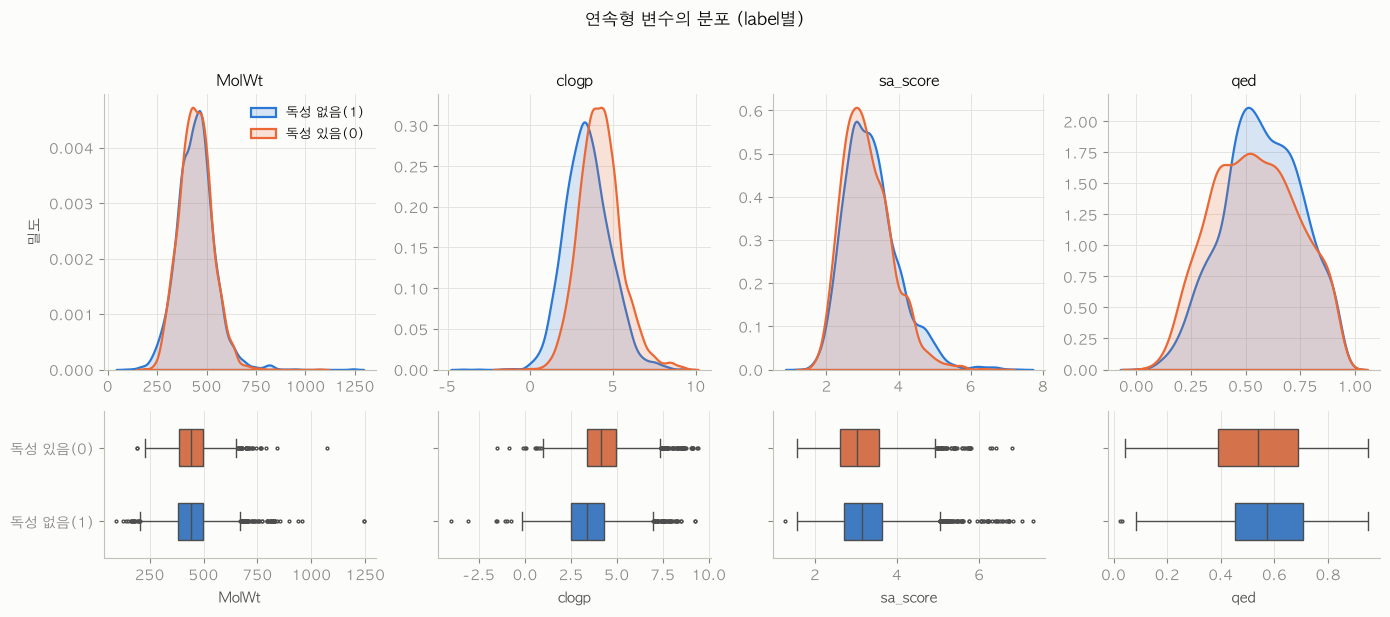

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6), gridspec_kw={"height_ratios": [3, 1.6]})
for j, c in enumerate(CONT):
    for lab in (1, 0):
        sns.kdeplot(df.loc[y == lab, c], ax=axes[0, j], color=PAL[lab], fill=True, alpha=0.18, linewidth=1.6, label=LABEL_NAME[lab], common_norm=False)
    axes[0, j].set_title(c)
    axes[0, j].set_xlabel("")
    axes[0, j].set_ylabel("밀도" if j == 0 else "")
    sns.boxplot(data=df, x=c, y="label", orient="h", palette=PAL, hue="label", legend=False, ax=axes[1, j], width=0.5, linewidth=1, fliersize=2)
    axes[1, j].set_yticklabels([LABEL_NAME[0], LABEL_NAME[1]] if j == 0 else ["", ""])
    axes[1, j].set_ylabel("")
    axes[1, j].grid(axis="y", visible=False)
axes[0, 0].legend(frameon=False, fontsize=9)
fig.suptitle("연속형 변수의 분포 (label별)", y=1.02)
fig.tight_layout()
save(fig, "02_continuous_by_label.png")

## 5. 연속형 변수의 설명력 (label 대비)

`AUC`가 0.5에서 멀수록 설명력이 크다. `sign` +1은 값이 클수록 독성 없음(1) 쪽이라는 뜻이다.
`best_f1`은 변수 하나에 임계값 하나를 두고 방향도 고른 단순 규칙의 최고 F1이다. 전체 train에서 임계값을 골랐으므로 **낙관적 참고치**이고, 기준선(전부 1 예측)과 비교하는 용도다.

In [7]:
def best_f1(x, y):
    # 방향(+/-)과 임계값을 모두 탐색한 최대 F1 (Positive = 1)
    best = 0.0
    for d in (1, -1):
        p, r, _ = precision_recall_curve(y, d * np.asarray(x, dtype=float))
        f = 2 * p * r / np.clip(p + r, 1e-12, None)
        best = max(best, float(np.nanmax(f)))
    return best


def eval_continuous(s, y):
    s = pd.Series(s).astype(float)
    x1, x0 = s[y == 1], s[y == 0]
    auc = roc_auc_score(y, s)
    sd = np.sqrt(((len(x1) - 1) * x1.var(ddof=1) + (len(x0) - 1) * x0.var(ddof=1)) / (len(s) - 2))
    return {
        "auc": auc, "gini": abs(2 * auc - 1), "sign": int(np.sign(auc - 0.5)),
        "spearman": stats.spearmanr(s, y)[0],
        "cohens_d": (x1.mean() - x0.mean()) / sd if sd > 0 else np.nan,
        "p": stats.mannwhitneyu(x1, x0, alternative="two-sided").pvalue,
        "best_f1": best_f1(s, y),
    }


cont_tbl = pd.DataFrame({c: eval_continuous(df[c], y) for c in CONT}).T.sort_values("gini", ascending=False)
print(f"(참고) F1 기준선 = {f1_all_pos:.4f}")
print(cont_tbl.round(4))
cont_tbl.to_csv(TAB / "continuous_explanatory_power.csv")

(참고) F1 기준선 = 0.7047
             auc    gini  sign  spearman  cohens_d       p  best_f1
clogp     0.3375  0.3251  -1.0   -0.2804   -0.5698  0.0000   0.7071
qed       0.5485  0.0969   1.0    0.0836    0.1686  0.0000   0.7047
sa_score  0.5413  0.0827   1.0    0.0713    0.1569  0.0000   0.7047
MolWt     0.4947  0.0107  -1.0   -0.0092   -0.0115  0.3999   0.7047


## 6. 다변량 분석: 연속형 변수 간 상관과 산점도

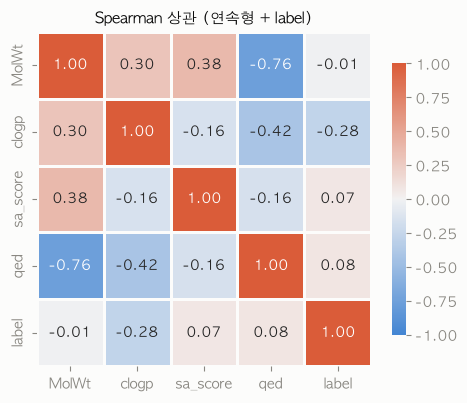

In [8]:
corr = df[CONT + ["label"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(5.4, 4.4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.diverging_palette(250, 20, s=80, l=55, center="light", as_cmap=True),
            vmin=-1, vmax=1, center=0, square=True, linewidths=2, linecolor=SURFACE, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Spearman 상관 (연속형 + label)")
ax.grid(False)
save(fig, "03_continuous_spearman_heatmap.png")

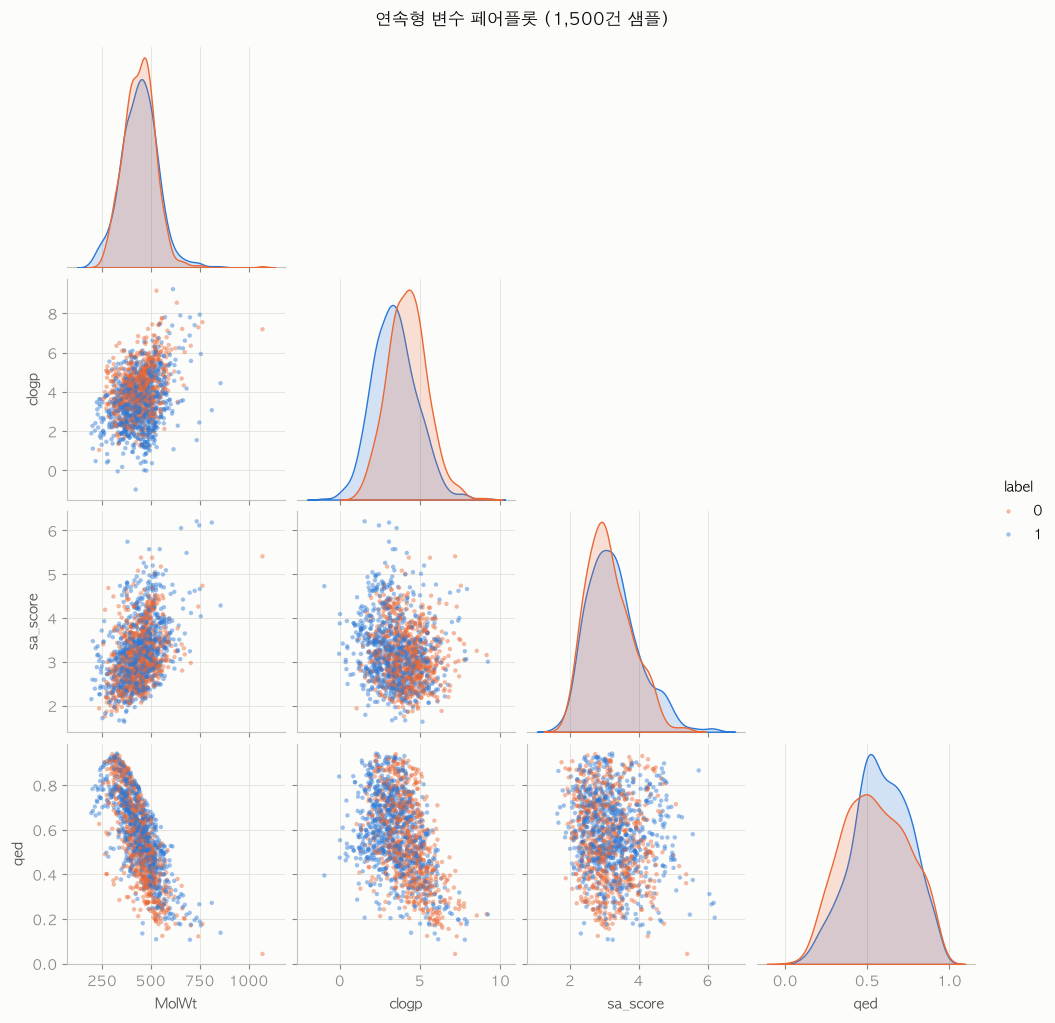

In [9]:
sample = df.sample(1500, random_state=42)
g = sns.pairplot(sample, vars=CONT, hue="label", palette=PAL, diag_kind="kde", corner=True,
                 plot_kws={"s": 10, "alpha": 0.45, "linewidth": 0}, diag_kws={"fill": True, "alpha": 0.2, "common_norm": False})
g.figure.suptitle("연속형 변수 페어플롯 (1,500건 샘플)", y=1.02)
g.figure.savefig(FIG / "04_continuous_pairplot.png")
plt.show()

## 7. SMILES 파생변수 (RDKit)

SMILES는 8,349개가 전부 고유한 문자열(식별자에 가깝다)이라 그대로는 변수로 쓸 수 없다. 분자 기술자로 수치화하고 SMILES는 파생에만 쓴다.
기존 컬럼과 사실상 같은 기술자(`MolWt`, `clogp`, `qed`)는 중복이므로 먼저 걸러낸다.

In [10]:
rd_raw = compute_rdkit_descriptors(df["SMILES"])
parse_fail = int(rd_raw.isna().all(axis=1).sum())
print(f"RDKit 기술자 {rd_raw.shape[1]}개, SMILES 파싱 실패 {parse_fail}건")

nan_cols = rd_raw.columns[rd_raw.isna().any()]
print("결측이 있는 기술자:", {c: int(rd_raw[c].isna().sum()) for c in nan_cols})
const_cols = [c for c in rd_raw.columns if rd_raw[c].nunique(dropna=True) <= 1]
print(f"상수 기술자 {len(const_cols)}개:", const_cols)

# 탐색용: 상수열 제외, 결측은 중앙값으로 대체(전체 기준이므로 Day2에서는 분할 후 학습 데이터로 다시 한다)
rd = rd_raw.drop(columns=const_cols)
rd = rd.fillna(rd.median())

# 기존 컬럼과의 중복 확인
pairs = {"MolWt": PREFIX + "MolWt", "clogp": PREFIX + "MolLogP", "qed": PREFIX + "qed"}
dup_check = pd.Series({f"{a} vs {b}": stats.spearmanr(df[a], rd[b])[0] for a, b in pairs.items()})
print(dup_check.round(4))

RDKit 기술자 217개, SMILES 파싱 실패 0건
결측이 있는 기술자: {'rd_BCUT2D_MWHI': 7, 'rd_BCUT2D_MWLOW': 7, 'rd_BCUT2D_CHGHI': 7, 'rd_BCUT2D_CHGLO': 7, 'rd_BCUT2D_LOGPHI': 7, 'rd_BCUT2D_LOGPLOW': 7, 'rd_BCUT2D_MRHI': 7, 'rd_BCUT2D_MRLOW': 7}
상수 기술자 10개: ['rd_NumRadicalElectrons', 'rd_SMR_VSA8', 'rd_SlogP_VSA9', 'rd_fr_azo', 'rd_fr_diazo', 'rd_fr_epoxide', 'rd_fr_isocyan', 'rd_fr_isothiocyan', 'rd_fr_nitroso', 'rd_fr_thiocyan']
MolWt vs rd_MolWt      1.0
clogp vs rd_MolLogP    1.0
qed vs rd_qed          1.0
dtype: float64


In [11]:
dup_cols = [b for a, b in pairs.items() if abs(stats.spearmanr(df[a], rd[b])[0]) > 0.99]
rd = rd.drop(columns=dup_cols)
print("중복으로 제외:", dup_cols, "-> 파생변수", rd.shape[1], "개")

# 파생변수끼리의 다중공선성
rho = rd.corr(method="spearman").abs().to_numpy(copy=True)
np.fill_diagonal(rho, 0)
n_high = int((np.triu(rho) > 0.95).sum())
print(f"|Spearman| > 0.95인 파생변수 쌍: {n_high}개")

중복으로 제외: ['rd_MolWt', 'rd_MolLogP', 'rd_qed'] -> 파생변수 204 개


|Spearman| > 0.95인 파생변수 쌍: 66개


## 8. 핑거프린트 비트의 설명력

In [12]:
def eval_bits(X, y, names):
    X = np.asarray(X, dtype=np.int64)
    N1, N0, N = (y == 1).sum(), (y == 0).sum(), len(y)
    a = X[y == 1].sum(0)  # label 1 중 ON
    b = X[y == 0].sum(0)  # label 0 중 ON
    c, d = N1 - a, N0 - b
    on = a + b
    valid = (on > 0) & (on < N)
    with np.errstate(divide="ignore", invalid="ignore"):
        chi2 = N * (a * d - b * c) ** 2 / ((a + b) * (c + d) * (a + c) * (b + d))
    tpr, fpr = a / N1, b / N0
    out = pd.DataFrame({
        "gini": np.abs(tpr - fpr), "sign": np.sign(tpr - fpr).astype(int),
        "p": stats.chi2.sf(chi2, 1), "on_count": on,
        "odds_ratio": ((a + 0.5) * (d + 0.5)) / ((b + 0.5) * (c + 0.5)),
    }, index=names)
    return out[valid]


bit_tbl = pd.concat([eval_bits(df[cols].values, y, cols).assign(group=g) for g, cols in GROUPS.items()])
print(bit_tbl.groupby("group").size().rename("검정 가능 비트 수"))

group
ecfp    1024
fcfp    1024
ptfp     975
Name: 검정 가능 비트 수, dtype: int64


## 9. 전체 변수 설명력 랭킹 (같은 잣대)

In [13]:
base_tbl = cont_tbl[["gini", "sign", "p", "best_f1"]].assign(group="기존 연속형")
rd_tbl = pd.DataFrame({c: eval_continuous(rd[c], y) for c in rd.columns}).T[["gini", "sign", "p", "best_f1"]].assign(group="RDKit 파생")
rd_tbl["sign"] = rd_tbl["sign"].astype(int)

allf = pd.concat([base_tbl, rd_tbl, bit_tbl[["gini", "sign", "p", "group", "on_count", "odds_ratio"]]])
allf[["gini", "p"]] = allf[["gini", "p"]].astype(float)
allf["q"] = multipletests(allf["p"], method="fdr_bh")[1]
allf["sig_q05"] = allf["q"] < 0.05
allf = allf.sort_values("gini", ascending=False)
allf.index.name = "feature"
allf.to_csv(TAB / "feature_explanatory_power.csv")

summary = allf.groupby("group").agg(
    변수수=("gini", "size"), Gini_최대=("gini", "max"), Gini_중앙값=("gini", "median"),
    유의_q05=("sig_q05", "sum"),
)
summary["유의 비율(%)"] = (summary["유의_q05"] / summary["변수수"] * 100).round(1)
summary = summary.loc[["기존 연속형", "RDKit 파생", "ecfp", "fcfp", "ptfp"]]
print(summary.round(3))
summary.round(4).to_csv(TAB / "group_summary.csv")
print()
print(f"전체 {len(allf):,}개 중 q<0.05: {int(allf.sig_q05.sum()):,}개, Gini 최대 {allf.gini.max():.3f}, Gini>0.2: {int((allf.gini > 0.2).sum())}개")

           변수수  Gini_최대  Gini_중앙값  유의_q05  유의 비율(%)
group                                              
기존 연속형       4    0.325     0.090       3      75.0
RDKit 파생   204    0.279     0.038     139      68.1
ecfp      1024    0.183     0.007     449      43.8
fcfp      1024    0.174     0.004     383      37.4
ptfp       975    0.141     0.010     454      46.6

전체 3,231개 중 q<0.05: 1,428개, Gini 최대 0.325, Gini>0.2: 9개


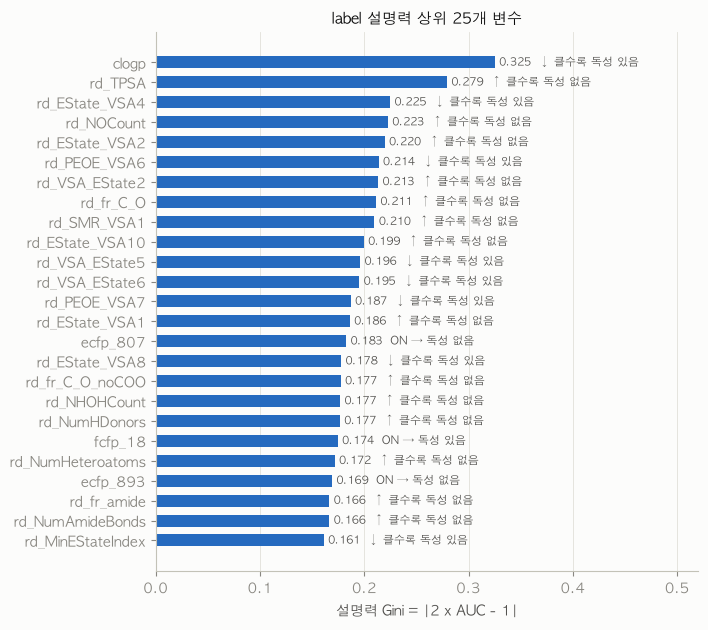

In [14]:
top = allf.head(25)
fig, ax = plt.subplots(figsize=(7, 7))
ypos = np.arange(len(top))[::-1]
ax.barh(ypos, top["gini"], color=C_ACCENT, height=0.6)
ax.set_yticks(ypos)
ax.set_yticklabels(top.index)
for yp, (name, r) in zip(ypos, top.iterrows()):
    arrow = "↑ 클수록 독성 없음" if r["sign"] > 0 else "↓ 클수록 독성 있음"
    if r["group"] in ("ecfp", "fcfp", "ptfp"):
        arrow = "ON → 독성 없음" if r["sign"] > 0 else "ON → 독성 있음"
    ax.text(r["gini"] + 0.004, yp, f"{r['gini']:.3f}  {arrow}", va="center", fontsize=8, color=INK2)
ax.set_xlim(0, top["gini"].max() * 1.6)
ax.set_xlabel("설명력 Gini = |2 x AUC - 1|")
ax.set_title("label 설명력 상위 25개 변수")
ax.grid(axis="y", visible=False)
save(fig, "05_top25_explanatory_power.png")

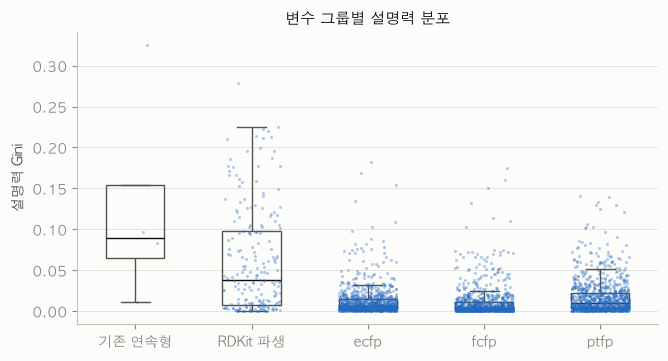

In [15]:
order = ["기존 연속형", "RDKit 파생", "ecfp", "fcfp", "ptfp"]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
sns.stripplot(data=allf, x="group", y="gini", order=order, color=C_ACCENT, size=2.2, alpha=0.35, jitter=0.25, ax=ax)
sns.boxplot(data=allf, x="group", y="gini", order=order, showfliers=False, boxprops={"facecolor": "none", "edgecolor": INK2}, whiskerprops={"color": INK2},
            capprops={"color": INK2}, medianprops={"color": INK}, width=0.5, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("설명력 Gini")
ax.set_title("변수 그룹별 설명력 분포")
ax.grid(axis="x", visible=False)
save(fig, "06_group_gini_distribution.png")

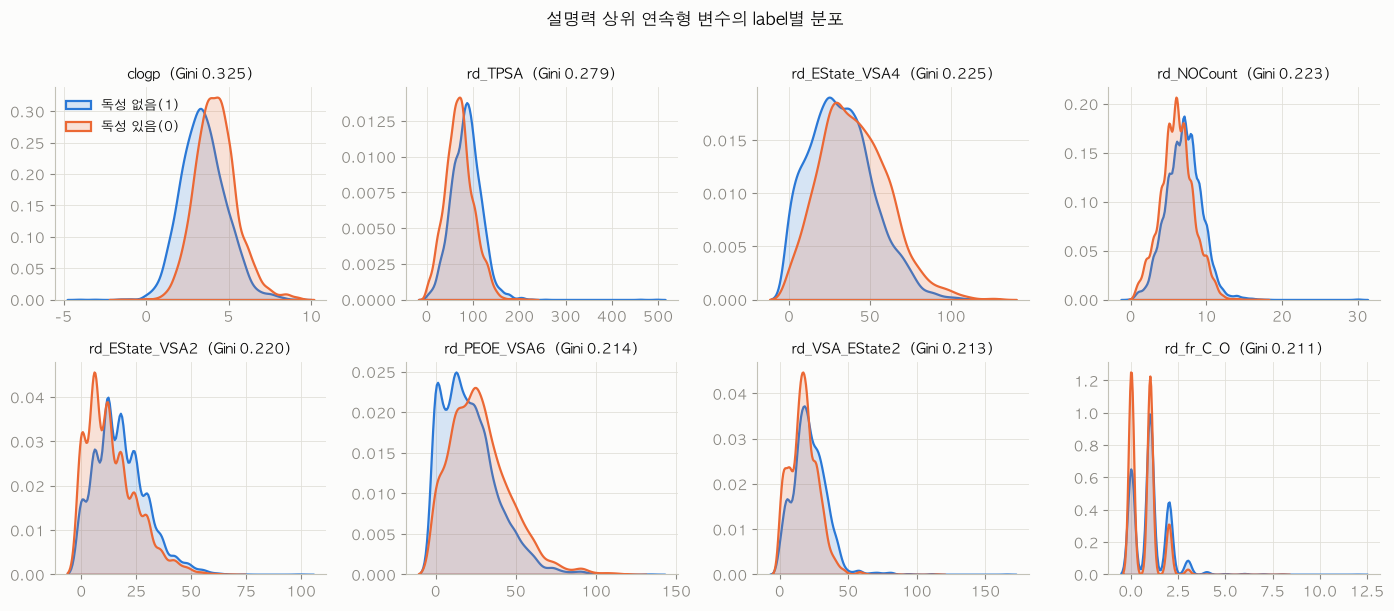

In [16]:
# 상위 파생변수 + 기존 연속형: label별 분포 (각 변수 상위 8개)
top_cont = allf[allf["group"].isin(["기존 연속형", "RDKit 파생"])].head(8).index.tolist()
data_cont = pd.concat([df[CONT], rd], axis=1)
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.ravel(), top_cont):
    for lab in (1, 0):
        sns.kdeplot(data_cont.loc[y == lab, c], ax=ax, color=PAL[lab], fill=True, alpha=0.18, linewidth=1.6, label=LABEL_NAME[lab], common_norm=False)
    ax.set_title(f"{c}  (Gini {allf.loc[c, 'gini']:.3f})", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
axes[0, 0].legend(frameon=False, fontsize=9)
fig.suptitle("설명력 상위 연속형 변수의 label별 분포", y=1.01)
fig.tight_layout()
save(fig, "07_top_continuous_by_label.png")

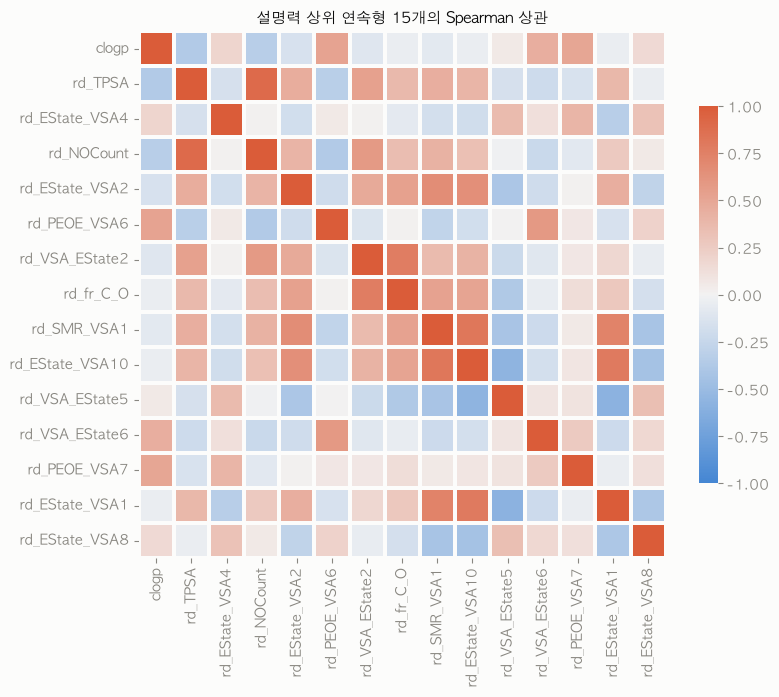

In [17]:
# 상위 파생변수끼리의 상관(다중공선성): 정보가 겹치는지 확인
top20 = allf[allf["group"].isin(["기존 연속형", "RDKit 파생"])].head(15).index.tolist()
cm = data_cont[top20].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(cm, cmap=sns.diverging_palette(250, 20, s=80, l=55, center="light", as_cmap=True), vmin=-1, vmax=1, center=0,
            square=True, linewidths=1.5, linecolor=SURFACE, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("설명력 상위 연속형 15개의 Spearman 상관")
ax.grid(False)
save(fig, "08_top_continuous_corr.png")

          독성 없음(1) ON 비율  독성 있음(0) ON 비율  전체 ON 건수    q
비트                                                     
ecfp_807          0.7155          0.5330      5279  0.0
fcfp_18           0.4044          0.5789      4041  0.0
ecfp_893          0.6319          0.4628      4632  0.0
fcfp_822          0.3917          0.5521      3881  0.0
ecfp_650          0.8252          0.6709      6302  0.0
fcfp_546          0.4782          0.6286      4565  0.0
ptfp_53           0.7779          0.6367      5957  0.0
ptfp_756          0.7977          0.6588      6131  0.0
ecfp_767          0.2336          0.3685      2464  0.0
ptfp_605          0.5867          0.4534      4391  0.0


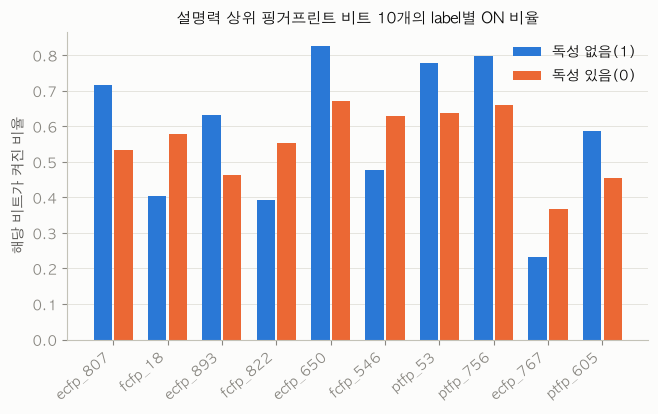

In [18]:
# 비트 효과 크기: 상위 비트의 ON 비율을 label별로 비교
topbits = allf[allf["group"].isin(["ecfp", "fcfp", "ptfp"])].head(10).index.tolist()
rows = []
for c in topbits:
    rows.append({"비트": c, "독성 없음(1) ON 비율": df.loc[y == 1, c].mean(), "독성 있음(0) ON 비율": df.loc[y == 0, c].mean(),
                 "전체 ON 건수": int(df[c].sum()), "q": allf.loc[c, "q"]})
bit_top = pd.DataFrame(rows).set_index("비트")
print(bit_top.round(4))
bit_top.round(5).to_csv(TAB / "top_bits.csv")

fig, ax = plt.subplots(figsize=(7.5, 4))
xx = np.arange(len(bit_top))
w = 0.38
ax.bar(xx - w / 2, bit_top["독성 없음(1) ON 비율"], w - 0.04, color=C_POS, label=LABEL_NAME[1])
ax.bar(xx + w / 2, bit_top["독성 있음(0) ON 비율"], w - 0.04, color=C_NEG, label=LABEL_NAME[0])
ax.set_xticks(xx)
ax.set_xticklabels(bit_top.index, rotation=40, ha="right")
ax.set_ylabel("해당 비트가 켜진 비율")
ax.set_title("설명력 상위 핑거프린트 비트 10개의 label별 ON 비율")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
save(fig, "09_top_bits_on_rate.png")

## 10. 요약 수치

In [19]:
print(f"행 {len(df):,} / 열 {df.shape[1]:,} / 결측 {quality['결측값 총합']} / SMILES 중복 {quality['SMILES 중복 행']} / 파싱 실패 {parse_fail}")
print(f"label 1(독성 없음) {share[1]:.1%}, label 0(독성 있음) {share[0]:.1%}, F1 기준선(전부 1) {f1_all_pos:.3f}")
print()
print("설명력 상위 10")
print(allf.head(10)[["group", "gini", "sign", "q"]].round(4))
print()
print("연속형 단일 규칙 best_f1 (참고, 낙관적)")
print(allf[allf.group.isin(["기존 연속형", "RDKit 파생"])].head(5)[["gini", "best_f1"]].round(3))

행 8,349 / 열 3,078 / 결측 0 / SMILES 중복 0 / 파싱 실패 0
label 1(독성 없음) 54.4%, label 0(독성 있음) 45.6%, F1 기준선(전부 1) 0.705

설명력 상위 10
                    group    gini  sign    q
feature                                     
clogp              기존 연속형  0.3251  -1.0  0.0
rd_TPSA          RDKit 파생  0.2792   1.0  0.0
rd_EState_VSA4   RDKit 파생  0.2247  -1.0  0.0
rd_NOCount       RDKit 파생  0.2226   1.0  0.0
rd_EState_VSA2   RDKit 파생  0.2195   1.0  0.0
rd_PEOE_VSA6     RDKit 파생  0.2136  -1.0  0.0
rd_VSA_EState2   RDKit 파생  0.2132   1.0  0.0
rd_fr_C_O        RDKit 파생  0.2112   1.0  0.0
rd_SMR_VSA1      RDKit 파생  0.2097   1.0  0.0
rd_EState_VSA10  RDKit 파생  0.1994   1.0  0.0

연속형 단일 규칙 best_f1 (참고, 낙관적)
                 gini  best_f1
feature                       
clogp           0.325    0.707
rd_TPSA         0.279    0.710
rd_EState_VSA4  0.225    0.708
rd_NOCount      0.223    0.707
rd_EState_VSA2  0.220    0.705
